# Imports

In [155]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [156]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    total_depth_sample = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples 
    params["simulation"]["total_depth_sample"] = total_depth_sample #depth per sample in m
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])
    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Total depth samples: ", total_depth_sample)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [157]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  3200
Total depth samples:  3.125e-06
Step size:  4.166666666666667e-09 s
Maximal acquisition depth: 0.01 m
Lateral step:  1.25e-05 m


# Import bf image

In [158]:
# bf_matrix = np.genfromtxt('./data/csv/bf_matrix.csv', delimiter=',').reshape(params["simulation"]["samples"], params["simulation"]["lateral_resolution"])

In [ ]:
bf_matrix = np.genfromtxt('./data_nsi/csv/beamformed/env_nsi.csv', delimiter=',').reshape(params["simulation"]["samples"], params["simulation"]["lateral_resolution"])

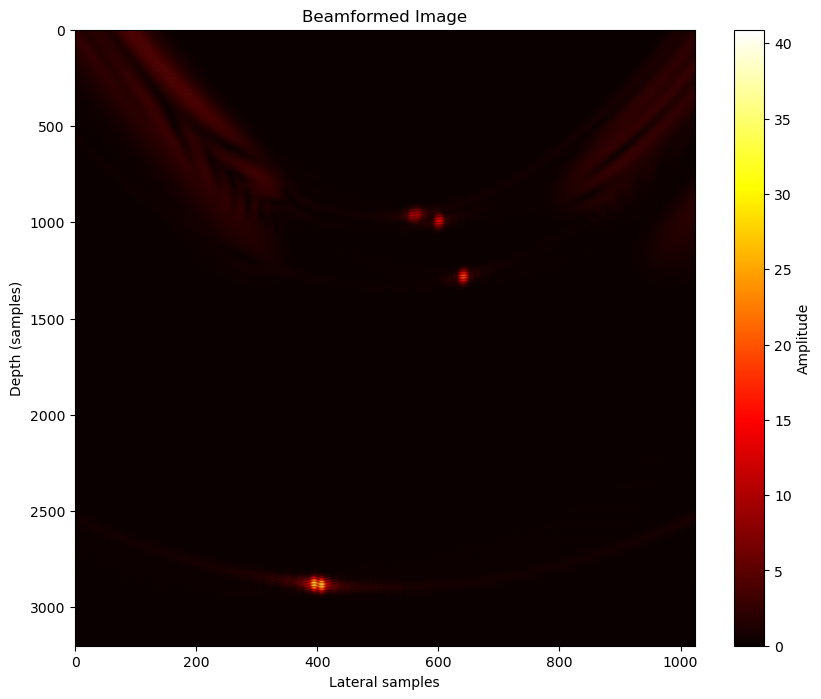

In [160]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Lateral samples")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.show()

# Rescale image

C:\Users\Acer\AppData\Local\Temp\ipykernel_8024\3454839100.py:7: RuntimeWarning: divide by zero encountered in log10
  im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')
C:\Users\Acer\AppData\Local\Temp\ipykernel_8024\3454839100.py:7: RuntimeWarning: invalid value encountered in log10
  im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')


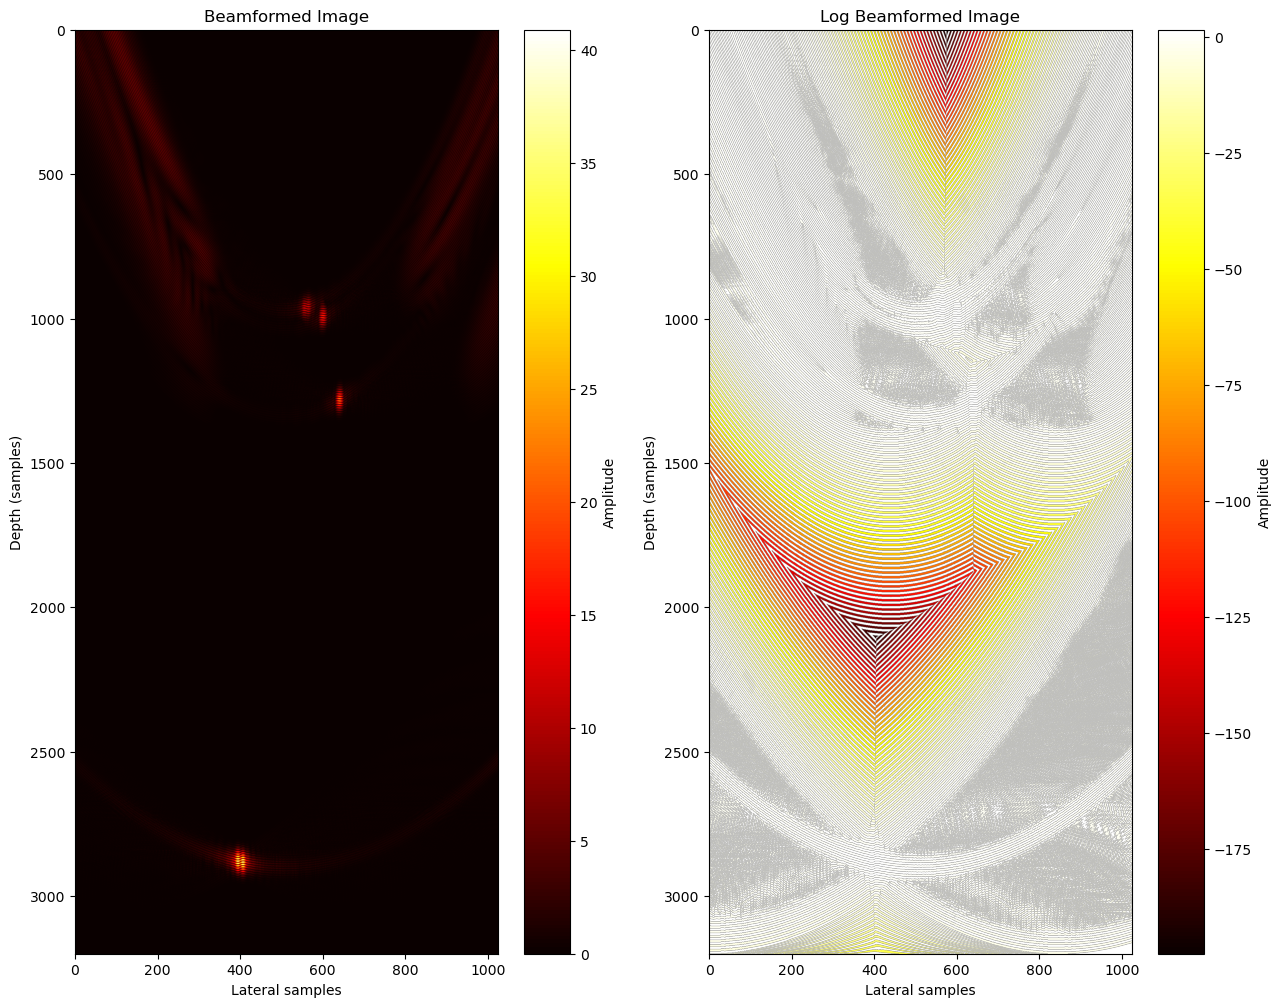

In [161]:
fig, ax = plt.subplots(1,2, figsize=(15, 12))
im0 = ax[0].imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
ax[0].set_title("Beamformed Image")
ax[0].set_xlabel("Lateral samples")
ax[0].set_ylabel("Depth (samples)")
fig.colorbar(im0, label="Amplitude", ax=ax[0])
im1 = ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')
ax[1].set_title("Log Beamformed Image") 
ax[1].set_xlabel("Lateral samples")
ax[1].set_ylabel("Depth (samples)")
fig.colorbar(im1, label="Amplitude", ax=ax[1])
plt.show()

In [162]:
#return the maximum value of the beamformed image
max_val = np.max(np.abs(bf_matrix))
print("Maximum value of the beamformed image: ", max_val)

Maximum value of the beamformed image:  40.9026437098119


# Get image zone

In [163]:
def extract_highest_value_region(bf_matrix, submatrix_size=100):
    row, col = np.unravel_index(np.argmax(np.abs(bf_matrix)), bf_matrix.shape)
    
    half_size = int(submatrix_size/2)
    row_start = row - half_size if row - half_size >= 0 else 0
    row_end = row + half_size if row + half_size < bf_matrix.shape[0] else bf_matrix.shape[0]
    col_start = col - half_size if col - half_size >= 0 else 0
    col_end = col + half_size if col + half_size < bf_matrix.shape[1] else bf_matrix.shape[1]

    print("Row start: ", row_start)
    print("Row end: ", row_end)
    print("Col start: ", col_start)
    print("Col end: ", col_end)

    return bf_matrix[row_start:row_end, col_start:col_end]

In [164]:
high_energy_zone = extract_highest_value_region(bf_matrix, submatrix_size=120)
print("High energy zone shape: ", high_energy_zone.shape)

Row start:  2821
Row end:  2941
Col start:  346
Col end:  466
High energy zone shape:  (120, 120)


# Visualize lobes

In [165]:
selected_res_zone = high_energy_zone

In [166]:
max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(selected_res_zone)), selected_res_zone.shape)

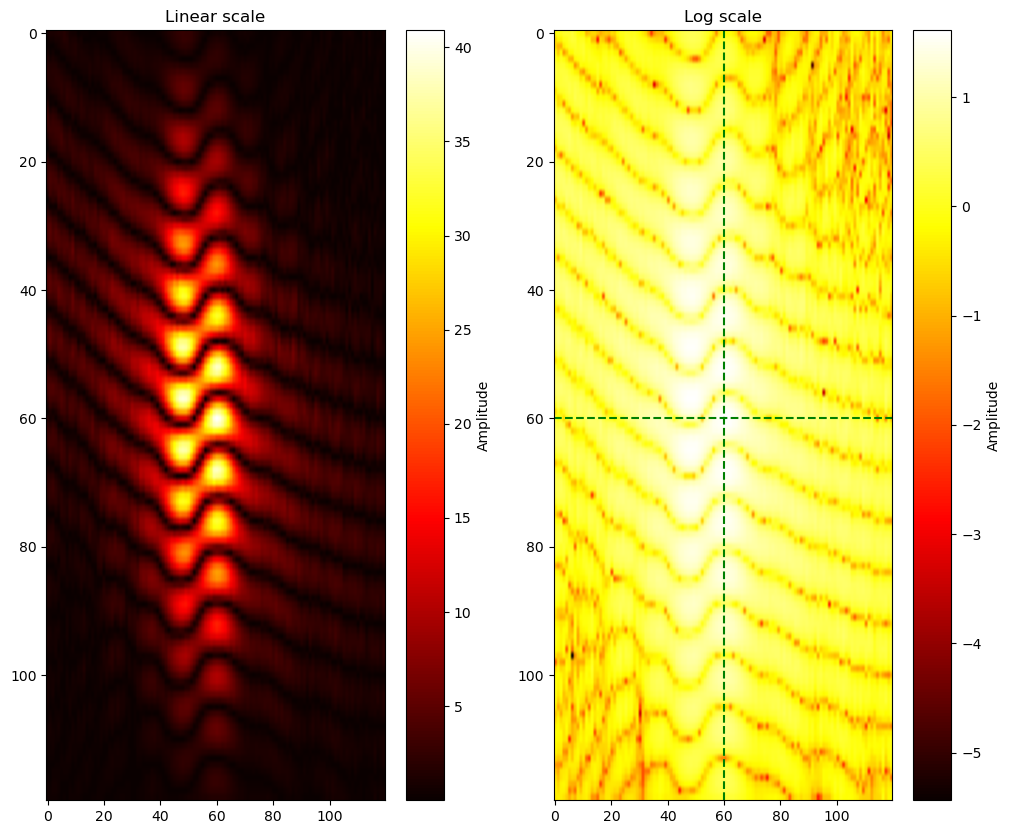

In [167]:
fig, ax = plt.subplots(1,2, figsize=(12, 10))
im0 = ax[0].imshow(np.abs(selected_res_zone), cmap='hot', aspect='auto')
ax[0].set_title("Linear scale")
plt.colorbar(im0, label="Amplitude", ax=ax[0])
im1 = ax[1].imshow(np.log10(np.abs(selected_res_zone)), cmap='hot', aspect='auto')
ax[1].set_title("Log scale")
ax[1].axhline(y=max_val_row, color='g', linestyle='--')
ax[1].axvline(x=max_val_col, color='g', linestyle='--')
plt.colorbar(im1, label="Amplitude", ax=ax[1])
plt.show()

# Metrics

In [168]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

## Lateral res (horizontal)

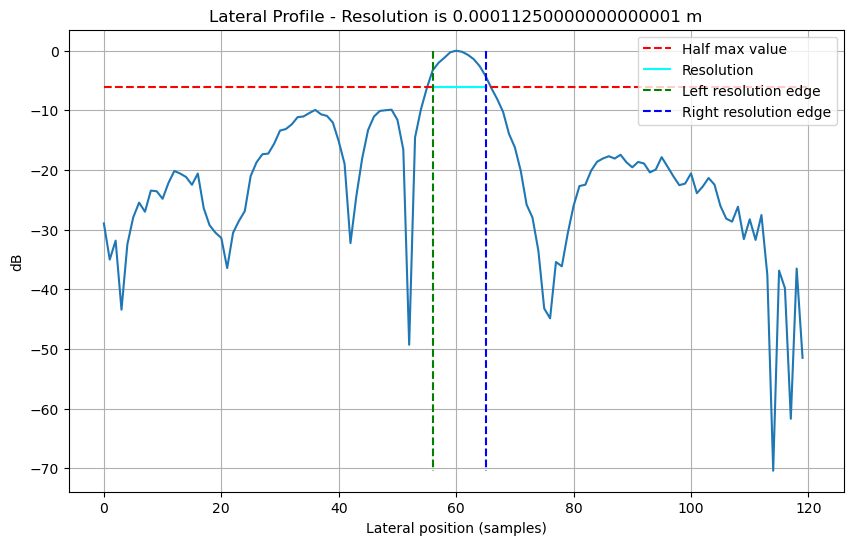

In [169]:
lateral_profile =  20 * np.log10(np.abs(selected_res_zone[max_val_row, :]) / np.max(np.abs(selected_res_zone[max_val_row, :]))) #we take values along the row with maximum value

lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

plt.figure(figsize=(10, 6))
plt.plot(lateral_profile)
plt.title(f"Lateral Profile - Resolution is {lat_res * params['simulation']['lateral_step']} m")
plt.xlabel("Lateral position (samples)")
plt.ylabel("dB")
plt.grid(True)
plt.hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(-6, lat_left_idx, lat_right_idx, colors='cyan', linestyles='-', label=f'Resolution')
plt.vlines(lat_left_idx, 0, min(lateral_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(lat_right_idx, 0, min(lateral_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()

## Axial resolution (vertical)

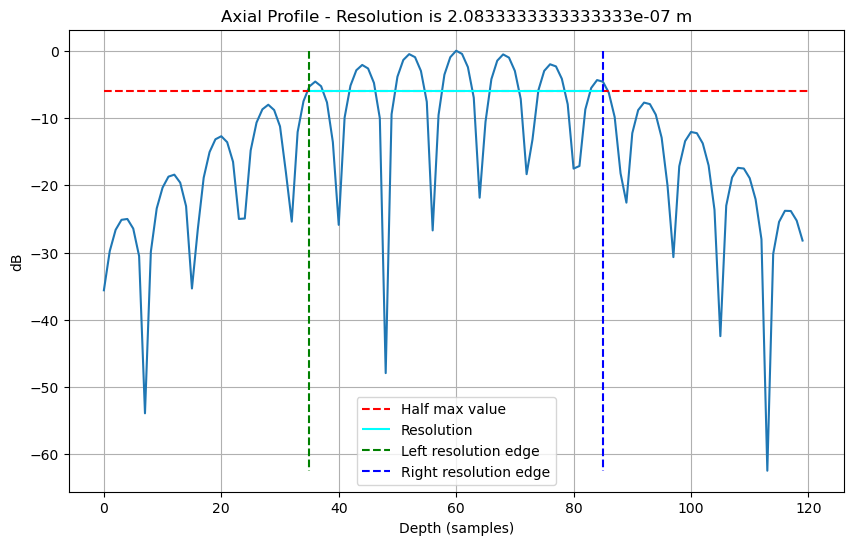

In [170]:
axial_profile = 20 * np.log10(np.abs(selected_res_zone[:, max_val_col]) / np.max(np.abs(selected_res_zone[:, max_val_col]))) #we take values along the column with maximum value

ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

plt.figure(figsize=(10, 6))
plt.plot(axial_profile)
plt.title(f"Axial Profile - Resolution is {ax_res * params["simulation"]["step_size"]} m")
plt.xlabel("Depth (samples)")
plt.ylabel("dB")
plt.grid(True)
plt.hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(-6, ax_left_idx, ax_right_idx, colors='cyan', linestyles='-', label=f'Resolution')
plt.vlines(ax_left_idx, 0, min(axial_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(ax_right_idx, 0, min(axial_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()